In [1]:
# Now lets look at my rent.com data

# Step 1, read in the imports :)

from pathlib import Path 
import geopandas as gpd
from shapely.geometry import Point
import pandas as pd
import matplotlib.pyplot as plt
import folium

In [2]:
Vic_Area_Zones = gpd.read_file(
    "data/ABS_Area_Zones/Vic_Area_Zones/Vic_Area_Zones.shp"
)

In [3]:
Rent_Dot_Data = pd.read_csv(
    "data/Rent.com_Scraped_Data/20260907_rentdoctomscrape.csv"
)

In [4]:

pd.set_option("display.max_columns", None)

In [6]:
########################
# Some preprocessing:
########################

# - a place with 12 & 16 & 20 car spaces
# some nan values for pets allowed
# - rent numbers of 42 or 90
# "Other property type"
# 50 bedrooms
# > 7 bathrroms
# nan for ensuites


Rent_Dot_Data["ensuites"].unique()

array([ 0.,  1., nan,  2.,  3.,  4., 12.,  6.,  9.,  5., 17.])

In [7]:
################################

# Coloumn choices:

# (1): Do we want to keep our scarped 
# suburb coloumn when the SA2 file has a localised code?

# (2): What do we do with outliers (Keep/remove/impute/further investigation)

# (3): Features & Walkability score, what do we want to extract out of them

# (4): id coloumn in scraped df, do we keep that?

#################################

In [8]:
# Now for the spatial join, my rent.com dataframe with my sa2 zones 


# first gotta convert the rent.com CSV into a GeoDataFrame

Rent_Dot_Geo = gpd.GeoDataFrame(
    Rent_Dot_Data.copy(),
    geometry=gpd.points_from_xy(
        Rent_Dot_Data["longitude"],
        Rent_Dot_Data["latitude"]
    ),
    crs="EPSG:4326"
)

# 2. Match CRS with the Victorian SA2 shapefile

Rent_Dot_Geo = Rent_Dot_Geo.to_crs(
    Vic_Area_Zones.crs
)

# now to join!!

Rent_Dot_With_Zones = gpd.sjoin(
    Rent_Dot_Geo,
    Vic_Area_Zones,
    how="left",
    predicate="within"
)

In [9]:
############################################################

# Now for some visulations I'm thinking avg rent number
# No. of listing per SA2 zone & Avg. proportion of 
# Apartments in sa2 zone
# Will also do folium plots too

#############################################################

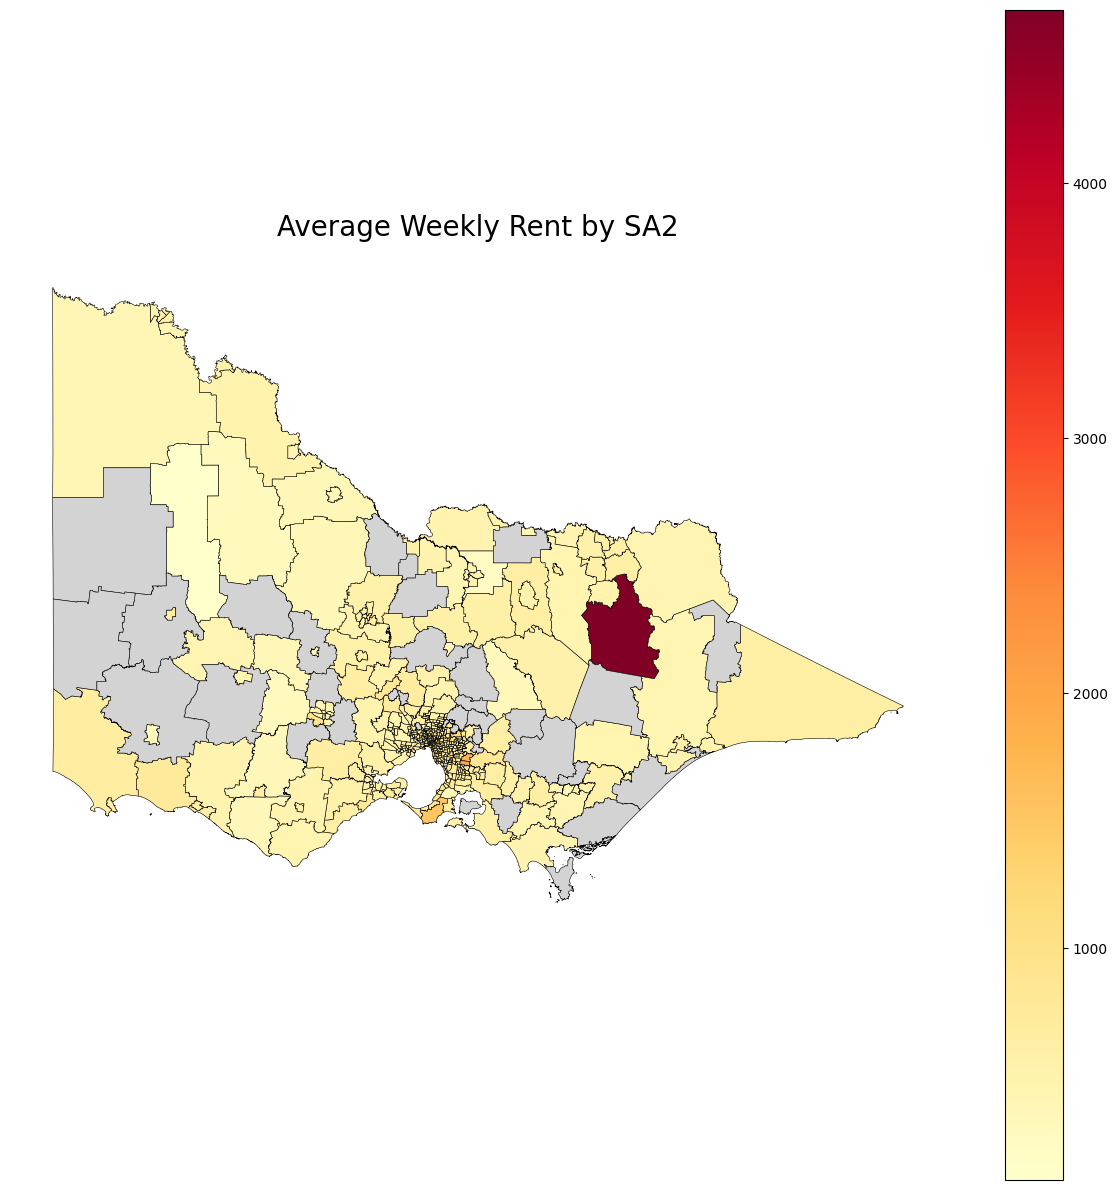

In [24]:

# First imma do an avg rental graph
# step one, need to calc the avg rent

SA2_Average_Rent = (
    Rent_Dot_With_Zones
    .groupby("SA2_NAME21", as_index=False)
    ["weekly_rent_number"]
    .mean()
)

SA2_Average_Rent = SA2_Average_Rent.rename(
    columns={
        "weekly_rent_number": "Average_Weekly_Rent"
    }
)

# 2. Join this onto sa2 


Vic_Rent_Map = Vic_Area_Zones.merge(
    SA2_Average_Rent,
    on="SA2_NAME21",
    how="left"
)

# Plot choropleth - matplot

fig, ax = plt.subplots(figsize=(12, 12))

Vic_Rent_Map.plot(
    column="Average_Weekly_Rent",
    cmap="YlOrRd",
    linewidth=0.4,
    edgecolor="black",
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "label": "No rental data"
    },
    ax=ax
)

ax.set_title(
    "Average Weekly Rent by SA2",
    fontsize=20,
    pad=15
)

ax.set_axis_off()

fig.savefig(
    "images/avg_rent_by_sa2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

In [19]:
### Folium plot of this info too

# Folium requires latitude/longitude coordinates
Vic_Rent_Folium = Vic_Rent_Map.to_crs(epsg=4326)

# Create map centred around Victoria/Melbourne
Rent_Map = folium.Map(
    location=[-37.8, 145.0],
    zoom_start=8,
    tiles="CartoDB positron"
)

# Create choropleth
folium.Choropleth(
    geo_data=Vic_Rent_Folium,
    data=Vic_Rent_Folium,
    columns=[
        "SA2_CODE21",
        "Average_Weekly_Rent"
    ],
    key_on="feature.properties.SA2_CODE21",
    fill_color="YlOrRd",
    fill_opacity=0.7,
    line_opacity=0.3,
    legend_name="Average Weekly Rent ($)"
).add_to(Rent_Map)

folium.GeoJson(
    Vic_Rent_Folium,
    style_function=lambda feature: {
        "fillColor": "transparent",
        "color": "transparent",
        "weight": 0
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "SA2_NAME21",
            "Average_Weekly_Rent"
        ],
        aliases=[
            "SA2:",
            "Average Weekly Rent: $"
        ],
        localize=True
    )
).add_to(Rent_Map)

Rent_Map.save(
    "images/average_rent_by_sa2.html"
)

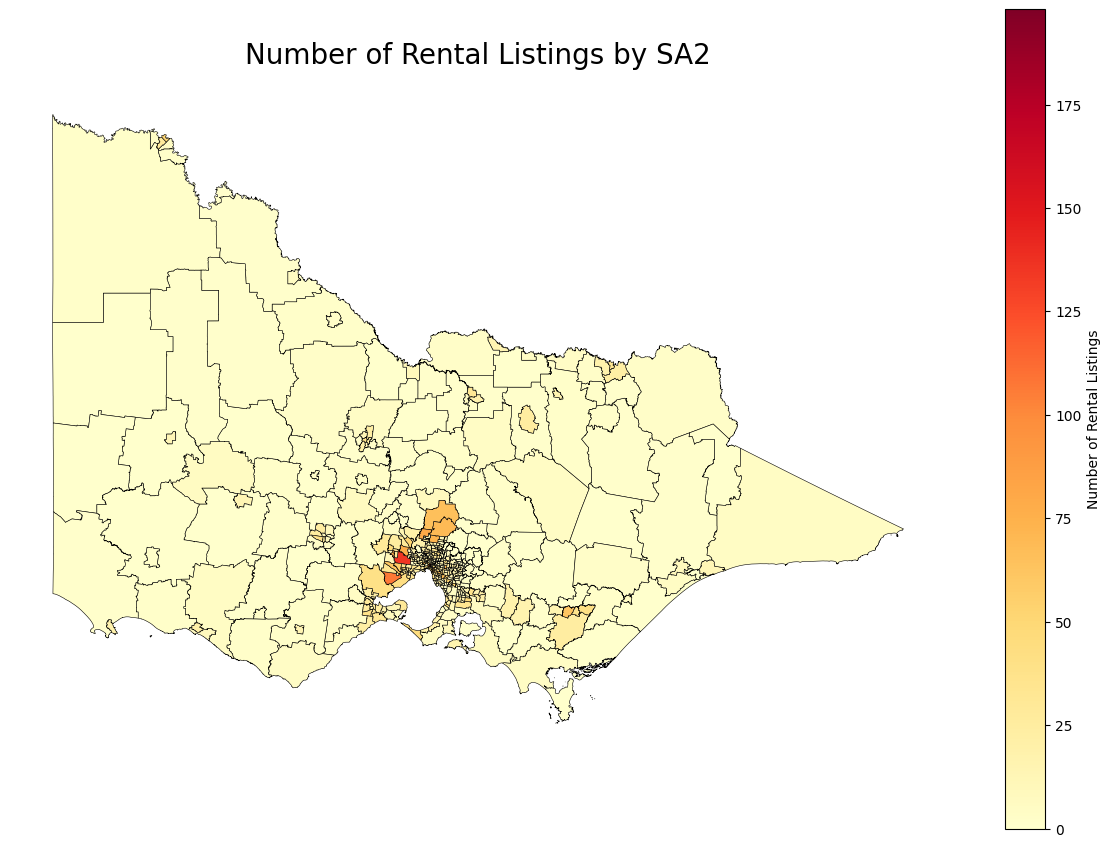

In [23]:
##### Now for number of listings


# Count no of listings by SA2


SA2_Listing_Counts = (
    Rent_Dot_With_Zones
    .groupby("SA2_NAME21")
    .size()
    .reset_index(name="Number_Of_Listings")
)

# Again, as per before, join onto sa2

Vic_Listing_Map = Vic_Area_Zones.merge(
    SA2_Listing_Counts,
    on="SA2_NAME21",
    how="left"
)

# Some areas will have na values, these should be zero
Vic_Listing_Map["Number_Of_Listings"] = (
    Vic_Listing_Map["Number_Of_Listings"]
    .fillna(0)
    .astype(int)
)

# Create choropleth

fig, ax = plt.subplots(figsize=(12, 12))

Vic_Listing_Map.plot(
    column="Number_Of_Listings",
    cmap="YlOrRd",
    linewidth=0.4,
    edgecolor="black",
    legend=True,
    legend_kwds={
        "label": "Number of Rental Listings",
        "shrink": 0.7
    },
    ax=ax
)

ax.set_title(
    "Number of Rental Listings by SA2",
    fontsize=20,
    pad=15
)

ax.set_axis_off()

fig.savefig(
    "images/no_rent_listings_by_sa2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

In [20]:

# now for the folium counterpart :)

Vic_Listing_Folium = Vic_Listing_Map.to_crs(
    epsg=4326
)

Listing_Map = folium.Map(
    location=[-37.8, 145.0],
    zoom_start=8,
    tiles="CartoDB positron"
)

# Add choropleth

folium.Choropleth(
    geo_data=Vic_Listing_Folium,
    data=Vic_Listing_Folium,
    columns=[
        "SA2_CODE21",
        "Number_Of_Listings"
    ],
    key_on="feature.properties.SA2_CODE21",
    fill_color="YlOrRd",
    fill_opacity=0.75,
    line_opacity=0.3,
    legend_name="Number of Rental Listings"
).add_to(Listing_Map)

folium.GeoJson(
    Vic_Listing_Folium,
    style_function=lambda feature: {
        "fillColor": "transparent",
        "color": "black",
        "weight": 0.3,
        "fillOpacity": 0
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "SA2_NAME21",
            "Number_Of_Listings"
        ],
        aliases=[
            "SA2 Zone:",
            "Number of Listings:"
        ],
        localize=True
    )
).add_to(Listing_Map)


Listing_Map.save(
    "images/no_listings_by_sa2.html"
)

In [14]:
#################################################################

# Now a final plot, prop of apartment listing in each sa2 zone

##################################################################

################################################################
# inorder to calc proportion of apartments per sa2 imma
# make a 'is apartment' indicator'
################################################################

Rent_Dot_With_Zones["Is_Apartment"] = (
    Rent_Dot_With_Zones["property_type"] == "Apartment"
).astype(int)



# now to calc apartment props

SA2_Apartment_Stats = (
    Rent_Dot_With_Zones
    .groupby("SA2_NAME21")
    .agg(
        Total_Listings=("property_type", "count"),
        Apartment_Listings=("Is_Apartment", "sum"),
        Apartment_Proportion=("Is_Apartment", "mean")
    )
    .reset_index()
)


# Convert proportion to percentage
SA2_Apartment_Stats["Apartment_Percent"] = (
    SA2_Apartment_Stats["Apartment_Proportion"] * 100
)

In [15]:
Vic_Apartment_Map = Vic_Area_Zones.merge(
    SA2_Apartment_Stats,
    on="SA2_NAME21",
    how="left"
)

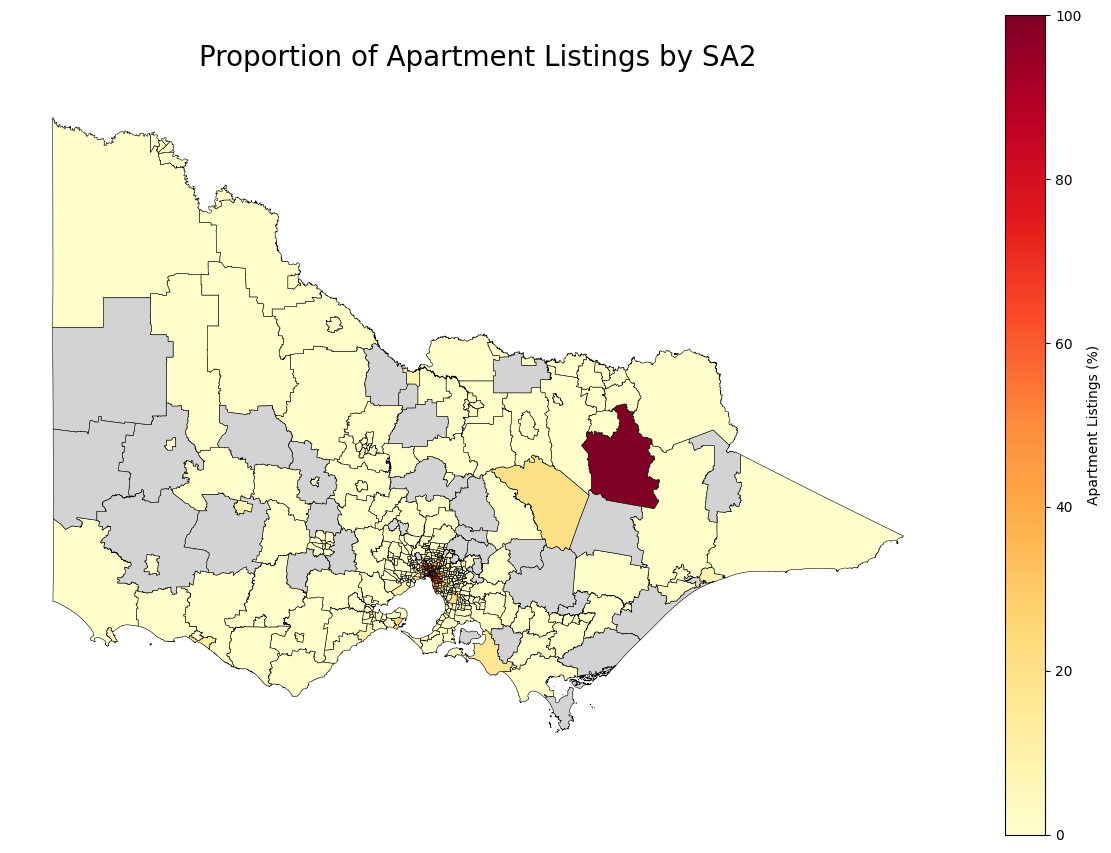

In [22]:

fig, ax = plt.subplots(
    figsize=(12, 12)
)

Vic_Apartment_Map.plot(
    column="Apartment_Percent",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidth=0.4,
    edgecolor="black",
    legend=True,
    legend_kwds={
        "label": "Apartment Listings (%)",
        "shrink": 0.7
    },
    missing_kwds={
        "color": "lightgrey",
        "label": "No rental data"
    },
    ax=ax
)

ax.set_title(
    "Proportion of Apartment Listings by SA2",
    fontsize=20,
    pad=15
)

ax.set_axis_off()

fig.savefig(
    "images/apartment_proportion_by_sa2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

In [21]:

Vic_Apartment_Folium = Vic_Apartment_Map.to_crs(
    epsg=4326
)

Apartment_Map = folium.Map(
    location=[-37.8, 145.0],
    zoom_start=8,
    tiles="CartoDB positron"
)


folium.Choropleth(
    geo_data=Vic_Apartment_Folium,
    data=Vic_Apartment_Folium,
    columns=[
        "SA2_CODE21",
        "Apartment_Percent"
    ],
    key_on="feature.properties.SA2_CODE21",
    fill_color="YlOrRd",
    fill_opacity=0.75,
    line_opacity=0.3,
    legend_name="Apartment Listings (%)",
    nan_fill_color="lightgrey",
    nan_fill_opacity=0.5
).add_to(Apartment_Map)

folium.GeoJson(
    Vic_Apartment_Folium,
    style_function=lambda feature: {
        "fillColor": "transparent",
        "color": "black",
        "weight": 0.3,
        "fillOpacity": 0
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "SA2_NAME21",
            "Apartment_Percent",
            "Apartment_Listings",
            "Total_Listings"
        ],
        aliases=[
            "SA2 Zone:",
            "Apartment Proportion (%):",
            "Apartment Listings:",
            "Total Listings:"
        ],
        localize=True
    )
).add_to(Apartment_Map)


Apartment_Map.save(
    "images/prop_apartments_by_sa2.html"
)